In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# Locate the project root
PROJECT_ROOT = Path.cwd()

# Handle launching Jupyter from either the project root or notebooks/
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "heart_disease_raw.csv"

# Column names for the Cleveland Heart Disease dataset
columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "num",
]

# The original CSV has no header row
df = pd.read_csv(
    DATA_PATH,
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [2]:
print("Column information:")
df.info()

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [3]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Total missing values:
6


In [4]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [5]:
df["target"] = (df["num"] > 0).astype(int)

print("Original target distribution:")
print(df["num"].value_counts().sort_index())

print("\nBinary target distribution:")
print(df["target"].value_counts().sort_index())

Original target distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64


Matplotlib is building the font cache; this may take a moment.


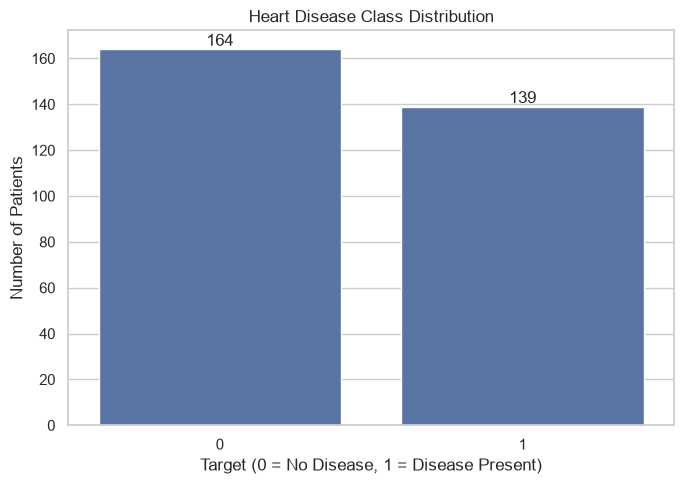

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="target"
)

ax.set_title("Heart Disease Class Distribution")
ax.set_xlabel("Target (0 = No Disease, 1 = Disease Present)")
ax.set_ylabel("Number of Patients")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

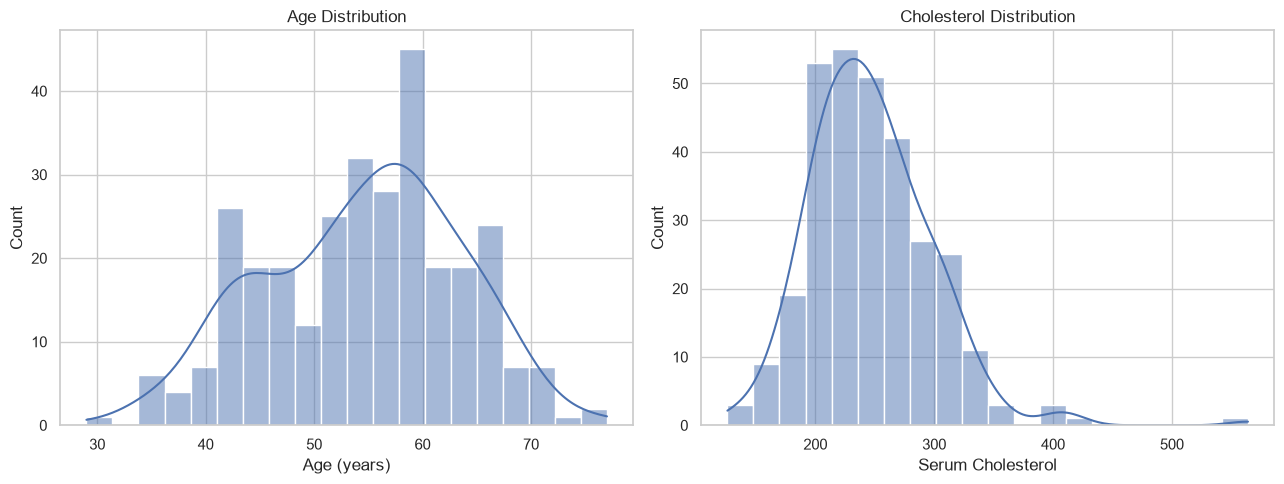

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age (years)")

sns.histplot(
    data=df,
    x="chol",
    bins=20,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Cholesterol Distribution")
axes[1].set_xlabel("Serum Cholesterol")

plt.tight_layout()
plt.show()

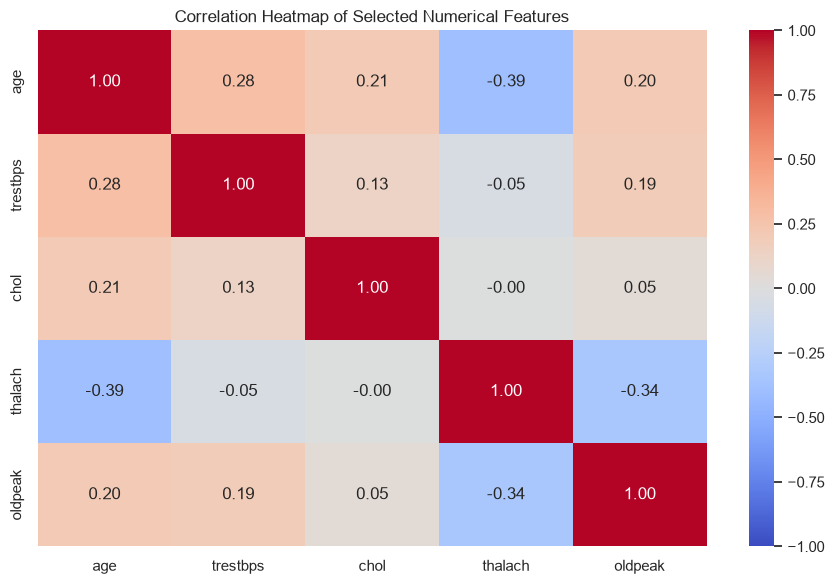

In [8]:
correlation_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

correlation_matrix = df[correlation_features].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Selected Numerical Features")
plt.tight_layout()
plt.show()